# Moved, or appeared? Transport-consistency of graph signals with the barycentric coding model

Graph signal processing (GSP; Shuman et al. 2013, Ortega et al. 2018) models a signal on the nodes of
a graph *linearly*: as a combination of Fourier modes, wavelets, or the atoms of a learned dictionary. When
the atoms are nonnegative "states" of
the network, this is the linear mixing model of spectral unmixing: a snapshot $x$ is explained as
$x \approx \sum_i \lambda_i x_i$ with $\lambda$ on the simplex.

For quantities that **move along the edges**, such as people on a street network, vehicles, packets, or a
pollutant in a river system, superposition is the wrong algebra. Halfway through the morning commute
the city is not "half of the night-time city plus half of the office-hours city". That mixture has
everybody either still at home or already at work, and nobody on the roads in between. A linear model
explains the teleporting city perfectly and fails to explain the real one.

The **barycentric coding model** (BCM) replaces superposition with transport. A snapshot is coded as a
Wasserstein barycenter of reference states,

$$\nu = \operatorname*{arg\,min}_{\mu} \sum_i \lambda_i\, W^2(\rho_i, \mu),$$

and here $W$ is the discrete transport metric of Maas and of Chow, Huang, Li and Zhou, in which mass can
only travel along the graph's edges. This notebook proposes and tests one use of that model on graphs:

> **The BCM's analysis step is a test of transport-consistency.** It asks whether a snapshot can be
> produced by moving mass among known regimes *along the graph*, or whether mass has teleported,
> appeared from nowhere, or taken a route the regimes cannot explain.

The analysis returns two things for every snapshot:

* **coordinates** $\hat\lambda$, which read where the mass is in its journey (e.g. how far the commute has
  progressed) from a single snapshot;
* a **barycentric defect** $\delta$, in units of transport distance, which is $0$ exactly when the
  snapshot is a barycenter of the regimes and grows with how far it is from being one.

Along the way, a GSP view of the transport metric explains *why* the test works and why it ignores node
noise. Locally, $W$ is a low-pass, inverse-Laplacian norm (a resistance or $H^{-1}$ norm). That view also
shows what the test cannot be: **any first-order (linearized) version of it collapses back to linear
unmixing.** The test's transport-awareness lives entirely in the nonlinearity of the BCM.

**Contents**

1. A small city network and its regimes
2. The transport metric through a GSP lens
3. The BCM, its analysis step, and the barycentric defect
4. Moved, or appeared? Four snapshots
5. Calibration: normal states against three kinds of anomaly
6. A day in the city
7. Repairing a missing frame
8. Discussion and references

Running it top to bottom takes about two minutes. It uses `method="socp"` throughout the city
experiments, because the long, thin transports between districts are where shooting struggles (see the
README's *Choosing a method*).

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from cvxpy.error import SolverError
from IPython.display import Markdown, display
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from scipy.linalg import eigh

import graphtransport as gt
from graphtransport.gram import potential_gram_qp, simplex_qp
from graphtransport.shooting.explog import weighted_laplacian
from graphtransport.socp import geodesic_socp

# The shooting solver (used in section 2) runs many small torch operations, which gain nothing from
# torch's thread pool at these sizes; without this it warns once (TorchThreadsWarning).
torch.set_num_threads(1)
# torch's own notice that torch.jit is unsupported on Python 3.14+, raised inside torch.func; not ours
warnings.filterwarnings("ignore", message=".*torch.jit.script.*", category=FutureWarning)

# Colors: one sequential blue ramp for mass, three categorical slots for the three regimes, and neutral
# inks (with direct labels) for the methods, so that no color means two things.
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
MASS = LinearSegmentedColormap.from_list(
    "mass", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
REGIME_COLOR = {"Home": "#2a78d6", "Work": "#eb6834", "Stadium": "#1baf7a"}
ALERT = "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "figure.dpi": 110, "legend.frameon": False,
})

## 1. A small city network and its regimes

The network has four districts, each a 3×3 street grid: **Home** (residential), **Work** (downtown),
**Stadium**, and **Harbor**. Roads of four intersections join Home–Work, Work–Stadium, Stadium–Home and
Home–Harbor. The Markov chain is the simple random walk on this graph, so $\pi$ is proportional to
degree.

A *regime* is a typical state of the city. In it, 95% of the population is spread evenly over one
district's intersections, and 5% is spread over the whole network as background. The background keeps
every density strictly positive, as the transport geometry needs, and is realistic: somebody is always
somewhere. There are three regimes: night (Home), office hours (Work) and an event (Stadium). **No regime
puts mass in the Harbor.** That district is where unexplained mass will appear.

Densities are taken with respect to $\pi$, as everywhere in `graphtransport`. A density $\rho$ has
$\rho\cdot\pi = 1$, and the mass at node $x$ is $\rho_x\pi_x$. All the pictures show mass.

In [2]:
def build_city(block=3, road=4):
    """Four block x block grid districts joined by roads of `road` intermediate nodes.

    Returns the MarkovGraph (simple random walk), node coordinates, node names, a name -> index map,
    the districts' node lists and the roads' node lists."""
    centers = {"Home": (0.0, 0.0), "Work": (10.0, 0.0), "Stadium": (5.0, 8.5), "Harbor": (-6.0, 6.5)}
    names, xy, edges, districts = [], [], [], {}

    def add(name, at):
        names.append(name)
        xy.append(at)
        return len(names) - 1

    for d, (cx, cy) in centers.items():
        grid = {}
        for i in range(block):
            for j in range(block):
                grid[i, j] = add(f"{d}{i}{j}", (cx + i - (block - 1) / 2, cy + j - (block - 1) / 2))
                if i:
                    edges.append((grid[i, j], grid[i - 1, j]))
                if j:
                    edges.append((grid[i, j], grid[i, j - 1]))
        districts[d] = list(grid.values())

    def corner(d, toward):  # the district's intersection nearest the other district
        tx, ty = centers[toward]
        return min(districts[d], key=lambda v: (xy[v][0] - tx) ** 2 + (xy[v][1] - ty) ** 2)

    roads = {}
    for a, b in [("Home", "Work"), ("Work", "Stadium"), ("Stadium", "Home"), ("Home", "Harbor")]:
        u, w = corner(a, b), corner(b, a)
        prev, roads[a, b] = u, []
        for k in range(1, road + 1):
            f = k / (road + 1)
            v = add(f"{a}-{b}{k}", ((1 - f) * xy[u][0] + f * xy[w][0], (1 - f) * xy[u][1] + f * xy[w][1]))
            edges.append((prev, v))
            roads[a, b].append(v)
            prev = v
        edges.append((prev, w))

    A = np.zeros((len(names), len(names)))
    for u, v in edges:
        A[u, v] = A[v, u] = 1.0
    G = gt.MarkovGraph(*gt.markov_chain_from_adjacency_matrix(A))
    return G, np.array(xy), names, {nm: i for i, nm in enumerate(names)}, districts, roads


G, XY, NAMES, IDX, DISTRICTS, ROADS = build_city()
PI = G.pi


def spread(nodes, floor=0.05):
    """The density with (1 - floor) of the mass spread evenly over `nodes` and `floor` spread as pi."""
    p = np.zeros(G.n)
    p[nodes] = 1.0 / len(nodes)
    return ((1 - floor) * p + floor * PI) / PI


REGIMES = ["Home", "Work", "Stadium"]
R = {d: spread(DISTRICTS[d]) for d in DISTRICTS}
REFS = [R[d] for d in REGIMES]
print(G)

MarkovGraph(n=52, |E|=68, mean=GeometricMean())


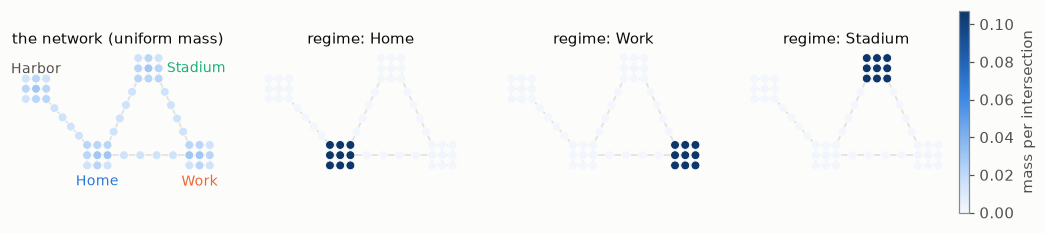

In [3]:
def draw(ax, rho, title=None, vmax=None, note=None, note_color=INK):
    """Draw the mass rho * pi on the city: streets in gray, one disc per intersection."""
    mass = rho * PI
    segs = [[XY[x], XY[y]] for x, y in G.E]
    ax.add_collection(LineCollection(segs, colors=GRID, linewidths=1.2, zorder=1))
    sc = ax.scatter(XY[:, 0], XY[:, 1], c=mass, cmap=MASS, vmin=0, vmax=vmax or mass.max(), s=34,
                    edgecolors=SURFACE, linewidths=0.6, zorder=2)
    ax.set_aspect("equal")
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10, color=INK)
    if note:
        ax.text(0.5, -0.04, note, transform=ax.transAxes, ha="center", va="top", fontsize=9.5, color=note_color)
    return sc


VMAX = max((R[d] * PI).max() for d in REGIMES)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
draw(axes[0], np.ones(G.n), "the network (uniform mass)", vmax=VMAX)
for d, (cx, cy, ha) in {"Home": (0, -2.6, "center"), "Work": (10, -2.6, "center"), "Stadium": (6.8, 8.5, "left"),
                         "Harbor": (-6, 8.4, "center")}.items():
    axes[0].text(cx, cy, d, ha=ha, va="center", fontsize=9, color=REGIME_COLOR.get(d, INK2))
for ax, d in zip(axes[1:], REGIMES, strict=True):
    sc = draw(ax, R[d], f"regime: {d}", vmax=VMAX)
fig.colorbar(sc, ax=axes, shrink=0.7, pad=0.01, label="mass per intersection")
plt.show()

## 2. The transport metric through a GSP lens

GSP's basic objects are the graph Laplacian and the graph Fourier basis it defines. The discrete transport
metric is built from the same object, with weights that depend on where the mass is.

**The tangent space.** A curve of densities $\rho_t$ moves by a potential $\varphi_t$ on the nodes:
$\pi \odot \dot\rho = L(\rho)\,\varphi$, where

$$L(\nu) = \nabla^{\top} \operatorname{diag}\big(\kappa_e\,\theta(\nu_x, \nu_y)\big)\,\nabla$$

is the graph Laplacian whose edge weights $\kappa_e$ are rescaled by a mean $\theta$ of the densities at
the edge's two ends (`graphtransport.shooting.explog.weighted_laplacian`). The speed of the curve is

$$\|\dot\rho\|^2_\nu = \varphi^{\top} L(\nu)\, \varphi = \sum_e \kappa_e\, \theta_e\, (\nabla \varphi)_e^2,$$

the **Dirichlet energy of the potential**. That is the quadratic form GSP uses to measure how smooth a
graph signal is, here applied to potentials rather than to densities.

**The linearization is low-pass.** For a small perturbation $s$ of the density, with $\pi\cdot s = 0$,

$$W^2(\nu,\ \nu + \varepsilon s)
  = \varepsilon^2\,(\pi \odot s)^{\top} L(\nu)^{\dagger}\, (\pi \odot s) + o(\varepsilon^2).$$

Robertson, Wan and Cloninger (2024) study this linearization as a resistance or dual-Sobolev ($H^{-1}$)
distance. In the graph Fourier basis at $\nu$, defined by the generalized eigenpairs
$L(\nu) u_k = \mu_k\, \Pi u_k$ with $u_k^{\top}\Pi u_j = \delta_{kj}$ and $\Pi = \operatorname{diag}(\pi)$,
it diagonalizes:

$$W^2(\nu,\ \nu + \varepsilon s) \approx \varepsilon^2 \sum_{k \ge 1} \frac{\hat s_k^2}{\mu_k},
  \qquad \hat s_k = u_k^{\top}\Pi s.$$

So the transport metric is a **graph filter with response $1/\mu_k$**:

| norm on a perturbation $s$ | spectral weight | it penalizes |
|---|---|---|
| $\ell^2(\pi)$ | $1$ | everything equally |
| Dirichlet energy $s^{\top}L s$ (GSP's smoothness prior) | $\mu_k$ | high frequencies: local wiggles |
| transport $W^2$ | $1/\mu_k$ | **low frequencies: mass moved far** |

At the uniform density with the geometric mean, $\theta \equiv 1$, so $L(\mathbf 1)$ is the ordinary
weighted Laplacian and $u_k$ are the random-walk Laplacian's eigenvectors. Below, the exact distance
(by shooting, which is accurate for these short transports) is checked against the predicted $1/\mu_k$
for eigenvectors across the spectrum.

13 distances by shooting in 4.5 s
largest relative gap between W^2/eps^2 and 1/mu_k: 2.79%


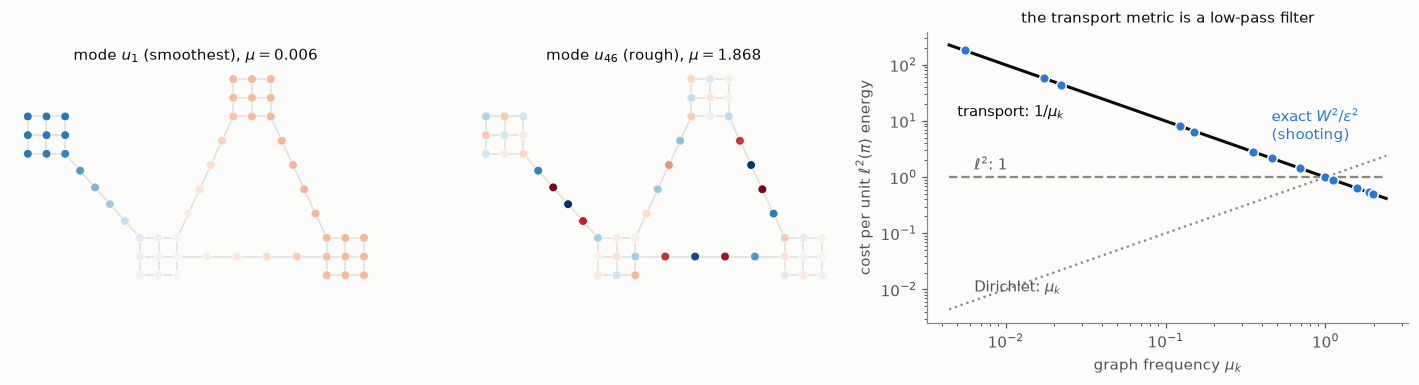

In [4]:
L1 = weighted_laplacian(G, np.ones(G.n)).toarray()
mu, U = eigh(L1, np.diag(PI))  # L u = mu Pi u, with U^T Pi U = I

ks = [1, 2, 3, 4, 6, 9, 13, 18, 24, 31, 39, 46, 51]
ratio = []
t0 = time.time()
for k in ks:
    eps = 0.2 / np.abs(U[:, k]).max()  # the perturbed density stays >= 0.8
    W = gt.transport_cost(G, np.ones(G.n), 1 + eps * U[:, k])  # shooting, the default
    ratio.append(W**2 / eps**2)  # ||U[:, k]||_pi = 1, so this is W^2 / ||eps s||^2
print(f"{len(ks)} distances by shooting in {time.time() - t0:.1f} s")
print("largest relative gap between W^2/eps^2 and 1/mu_k:",
      f"{max(abs(r * mu[k] - 1) for r, k in zip(ratio, ks, strict=True)):.2%}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
lim = np.abs(U[:, [1, 46]]).max()
for ax, k, label in [(axes[0], 1, "smoothest"), (axes[1], 46, "rough")]:
    segs = [[XY[x], XY[y]] for x, y in G.E]
    ax.add_collection(LineCollection(segs, colors=GRID, linewidths=1.2, zorder=1))
    ax.scatter(XY[:, 0], XY[:, 1], c=U[:, k], cmap="RdBu_r", vmin=-lim, vmax=lim, s=34,
               edgecolors=SURFACE, linewidths=0.6, zorder=2)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"mode $u_{{{k}}}$ ({label}), $\\mu = {mu[k]:.3f}$", fontsize=10)
ax = axes[2]
grid_mu = np.geomspace(mu[1] * 0.8, mu[-1] * 1.2, 200)
ax.loglog(grid_mu, 1 / grid_mu, color=INK, lw=2)
ax.loglog(grid_mu, np.ones_like(grid_mu), color=MUTED, lw=1.5, ls="--")
ax.loglog(grid_mu, grid_mu, color=MUTED, lw=1.5, ls=":")
ax.scatter([mu[k] for k in ks], ratio, s=40, color=REGIME_COLOR["Home"], edgecolors=SURFACE, zorder=3)
ax.text(mu[1] * 0.9, 12, "transport: $1/\\mu_k$", color=INK, fontsize=9.5)
ax.text(mu[1] * 1.15, 1.35, "$\\ell^2$: 1", color=INK2, fontsize=9.5)
ax.text(mu[1] * 1.15, mu[1] * 1.6, "Dirichlet: $\\mu_k$", color=INK2, fontsize=9.5)
ax.text(mu[13], ratio[ks.index(13)] * 2.2, "exact $W^2/\\varepsilon^2$\n(shooting)",
        color=REGIME_COLOR["Home"], fontsize=9.5, ha="left")
ax.set_xlabel("graph frequency $\\mu_k$")
ax.set_ylabel("cost per unit $\\ell^2(\\pi)$ energy")
ax.set_title("the transport metric is a low-pass filter", fontsize=10)
plt.tight_layout()
plt.show()

The exact distances sit on the $1/\mu_k$ curve over a factor of about 360 in frequency. Moving mass
from one side of the city to the other (the smoothest mode, a dipole between districts) costs about 360
times more than a rough, intersection-to-intersection rearrangement of the same $\ell^2$ size.

Two consequences for what follows:

* **Node noise is cheap.** Independent noise at each node spreads its energy evenly across the spectrum,
  and most of the spectrum is at large $\mu_k$, where the transport metric barely charges for it. A test
  phrased in the transport geometry should therefore be robust to sensor noise. Section 5 checks this.
* **The geometry is adaptive.** $L(\nu)$ depends on $\nu$. Wherever the density is small, as on an empty
  road, the edge weights $\theta(\nu)$ are small, so carrying mass across that road is expensive. The
  Fourier basis itself moves with the data. This is the nonlinearity that section 3 relies on.

## 3. The BCM, its analysis step, and the barycentric defect

Fix reference densities $\rho_1, \dots, \rho_k$ (the regimes) and write
$J_\lambda(\nu) = \sum_i \lambda_i W^2(\rho_i, \nu)$.

* **Synthesis:** $\lambda \mapsto \nu_\lambda = \arg\min_\nu J_\lambda(\nu)$ (`gt.barycenter`).
* **Analysis:** $\nu \mapsto \hat\lambda$ (`gt.analysis`). Let $\varphi_i = \nabla_\nu W^2(\nu, \rho_i)$
  be the potential that points from $\nu$ away from $\rho_i$ (it is $-2\log_\nu \rho_i$). The gradient of
  $J_\lambda$ at $\nu$ is $\sum_i \lambda_i \varphi_i$, and a barycenter is where it vanishes. So
  analysis solves the simplex quadratic program

$$\hat\lambda = \operatorname*{arg\,min}_{\lambda \in \Delta} \lambda^{\top} A \lambda,
  \qquad A_{ij} = \langle \varphi_i, \varphi_j \rangle_\nu = \varphi_i^{\top} L(\nu)\, \varphi_j,$$

  with a Gram matrix built from section 2's Dirichlet form (Werenski et al. 2022; for graphs, Gentile & Murphy 2026).

**The barycentric defect.** The minimum value is the squared length of the best achievable gradient. Its
square root, halved, is the defect

$$\delta(\nu) = \tfrac12 \big\|\nabla J_{\hat\lambda}(\nu)\big\|_\nu
  = \tfrac12 \sqrt{\hat\lambda^{\top} A\, \hat\lambda},$$

and it has units of transport distance. In a flat space $J_\lambda(x) = \sum_i \lambda_i |x - x_i|^2$ has
gradient $2(x - \sum_i \lambda_i x_i)$, so $\delta$ is *exactly* the distance from $x$ to its
reconstruction $\sum_i \hat\lambda_i x_i$: the residual of the linear model. On the graph, $\delta$ is the
tangent-space estimate of the distance from $\nu$ to its reconstruction $\nu_{\hat\lambda}$, and it
vanishes exactly at barycenters. We report it relative to the smallest distance between two regimes,
$D = \min_{i \neq j} W(\rho_i, \rho_j)$, so that $\delta / D = 0.1$ reads as "a tenth of the way from one
regime to the nearest other".

*Why not divide by $\sqrt{J}$ instead?* Since $\|\varphi_i\|_\nu = 2W(\nu, \rho_i)$, the ratio
$\sqrt{\hat\lambda^{\top} A \hat\lambda \,/\, \sum_i \hat\lambda_i A_{ii}} = \|\nabla \sqrt{J_{\hat\lambda}}(\nu)\|$
is the slope of the root-mean-square distance to the regimes. It lies in $[0, 1]$ and is tempting, but
next to a regime $\sqrt{J} \approx W(\cdot, \rho_i)$, whose slope is $1$ however small the deviation. A
night-time frame with a little sensor noise would score $1$. The slope measures the *direction* of the
deviation; a test needs its *size*.

**Four codings, one quadratic program.** Every model compared below minimizes $\lambda^{\top}B\lambda$
over the simplex, for a Gram matrix $B$ of *differences* $d_i$ between the snapshot and each regime, and
reports its residual $\|\sum_i \hat\lambda_i d_i\|$ relative to the regimes' separation in the same
geometry. The models differ only in the differences and the inner product:

| model | difference $d_i$ | inner product | states with zero defect |
|---|---|---|---|
| **$\ell^2$ unmixing** | $\pi \odot (\rho_i - \nu)$ | Euclidean | linear mixtures $\sum_i \lambda_i\rho_i$ |
| **first-order transport** | $\pi \odot (\rho_i - \nu)$ | $L(\nu)^{\dagger}$ | linear mixtures, again |
| **LOT** at base $\sigma$ | $\log_\sigma \rho_i - \log_\sigma \nu$ | $L(\sigma)$ | mixtures in the chart at $\sigma$ |
| **BCM** | $\log_\nu \rho_i$ | $L(\nu)$ | **barycenters** |

$\ell^2$ unmixing is the linear mixing model of spectral unmixing (Keshava & Mustard 2002). The
first-order coding uses the $H^{-1}$ norm of section 2. LOT is linear optimal transport (Wang et al. 2013),
whose barycentric coding Werenski et al. (2025) analyze; here its base point $\sigma$ is the uniform city.

The second row is worth a sentence. Because $\sum_i \lambda_i = 1$, we have
$\sum_i \lambda_i (\rho_i - \nu) = \sum_i \lambda_i \rho_i - \nu$. Under *any* positive-definite inner
product on mean-zero signals, the minimum is therefore zero exactly when $\nu$ is a linear mixture.
**No graph filter applied to linear differences, however well adapted, can see transport.** Replacing
$\ell^2$ by the low-pass transport norm changes which *errors* are cheap, but not which *states* are
explained. Transport-awareness is a genuinely nonlinear property of the BCM, which lives in how
$\log_\nu$ bends with $\nu$.

The cell below implements all four. Each returns $(\hat\lambda, \text{residual}/\text{separation})$, which is
$\delta / D$ for the BCM. The BCM's helper does what `gt.analysis(method="socp")` does, one level down, so
that it can also return the defect. It is checked against `gt.analysis` on one snapshot.

In [5]:
def socp(solve, Ns=(10, 12, 8, 14)):
    """solve(N) at the SOCP's default N=10, retried at a neighboring N if the conic solver fails.

    Clarabel occasionally stops on one discretization of these long, thin transports, either with a
    numerical error or at reduced accuracy (which graphtransport rejects rather than accepts). A
    neighboring N solves the same problem."""
    for N in Ns:
        try:
            return solve(N)
        except (SolverError, RuntimeError) as exc:
            if isinstance(exc, RuntimeError) and "not optimal" not in str(exc):
                raise
            socp.retries += 1
            last = exc
    raise last


socp.retries = 0


PAIRS = [(0, 1), (0, 2), (1, 2)]


def residual(lam, B):
    """||sum_i lam_i d_i|| for the Gram matrix B of the d_i."""
    return float(np.sqrt(max(lam @ B @ lam, 0.0)))


def separation(B):
    """min_{i != j} ||d_i - d_j||: how far apart the regimes are in the same geometry."""
    return min(np.sqrt(B[i, i] + B[j, j] - 2 * B[i, j]) for i, j in PAIRS)


# The BCM's scale: the distance between the two closest regimes.
D_W = min(socp(lambda N, i=i, j=j: np.sqrt(geodesic_socp(G, REFS[i], REFS[j], N=N).W2)) for i, j in PAIRS)


def code_bcm(nu):
    """BCM analysis: potentials of the geodesics nu -> rho_i, their Gram matrix at nu, the simplex QP.
    Returns (lam_hat, delta / D) with delta = |grad J| / 2 (phi_i is the gradient of W^2, twice the log)."""
    def solve(N):
        phis = [geodesic_socp(G, nu, ref, N=N).phi0 for ref in REFS]
        return potential_gram_qp(G, nu, phis, return_system=True)

    lam, A = socp(solve)
    return lam, residual(lam, A) / 2 / D_W


def code_l2(nu):
    D = np.array([PI * (ref - nu) for ref in REFS])
    B = D @ D.T
    lam = simplex_qp(B)
    return lam, residual(lam, B) / separation(B)


def code_first_order(nu):
    D = np.array([PI * (ref - nu) for ref in REFS])
    B = D @ np.linalg.pinv(weighted_laplacian(G, nu).toarray()) @ D.T
    lam = simplex_qp(B)
    return lam, residual(lam, B) / separation(B)


SIGMA = np.ones(G.n)  # LOT's base point: the uniform city
L_SIGMA = weighted_laplacian(G, SIGMA).toarray()


def embed(nu):
    return socp(lambda N: geodesic_socp(G, SIGMA, nu, N=N).phi0)


REF_EMB = [embed(ref) for ref in REFS]


def code_lot(nu):
    e = embed(nu)
    D = np.array([x - e for x in REF_EMB])
    B = D @ L_SIGMA @ D.T
    lam = simplex_qp(B)
    return lam, residual(lam, B) / separation(B)


def synth(lam):
    """BCM synthesis by the SOCP, at the same discretization the analysis uses."""
    return socp(lambda N: gt.barycenter(G, REFS, lam, method="socp", N=N)[0])


METHODS = {"BCM": code_bcm, "LOT": code_lot, "first-order": code_first_order, "ℓ² unmixing": code_l2}

nu = synth([0.2, 0.3, 0.5])
lam_api = gt.analysis(G, nu, REFS, method="socp")
lam_here, d_here = code_bcm(nu)
print(f"regime scale D = {D_W:.2f}")
print("gt.analysis:   ", np.round(lam_api, 5))
print("code_bcm:      ", np.round(lam_here, 5), f" defect δ/D = {d_here:.1e}")

regime scale D = 12.62
gt.analysis:    [0.20004 0.29999 0.49997]
code_bcm:       [0.20004 0.29999 0.49997]  defect δ/D = 2.3e-04


Analysis recovers the synthesis weights $(0.2, 0.3, 0.5)$ and reports a defect at solver tolerance.
Synthesis and analysis use the same SOCP discretization ($N = 10$ time steps), so the BCM is exactly
self-consistent at that discretization, even though the SOCP's distances carry an $O(1/N)$ time error.

## 4. Moved, or appeared? Four snapshots

Four snapshots of the city:

1. **commute**: the morning commute half done, which is the BCM synthesis at $\lambda = (\tfrac12, \tfrac12, 0)$.
   Mass is on the Home–Work road.
2. **teleport**: the linear mixture $\tfrac12 \rho_{\text{Home}} + \tfrac12\rho_{\text{Work}}$. It has the
   same total mass in each district as a 50/50 split of the population, but nobody on the road. This is
   what linear interpolation between a night frame and an office-hours frame produces, and what a
   double-counting data-fusion bug produces.
3. **appear**: the commute, with 20% of the mass replaced by a gathering in the Harbor, where no regime
   puts mass.
4. **detour**: the commute, with 25% of the mass moved onto the Stadium–Home road, a route the regimes
   never use.

For each one the figure shows the snapshot (top) and what the BCM *thinks* it is: the barycenter
$\nu_{\hat\lambda}$ synthesized from the analyzed coordinates (bottom).

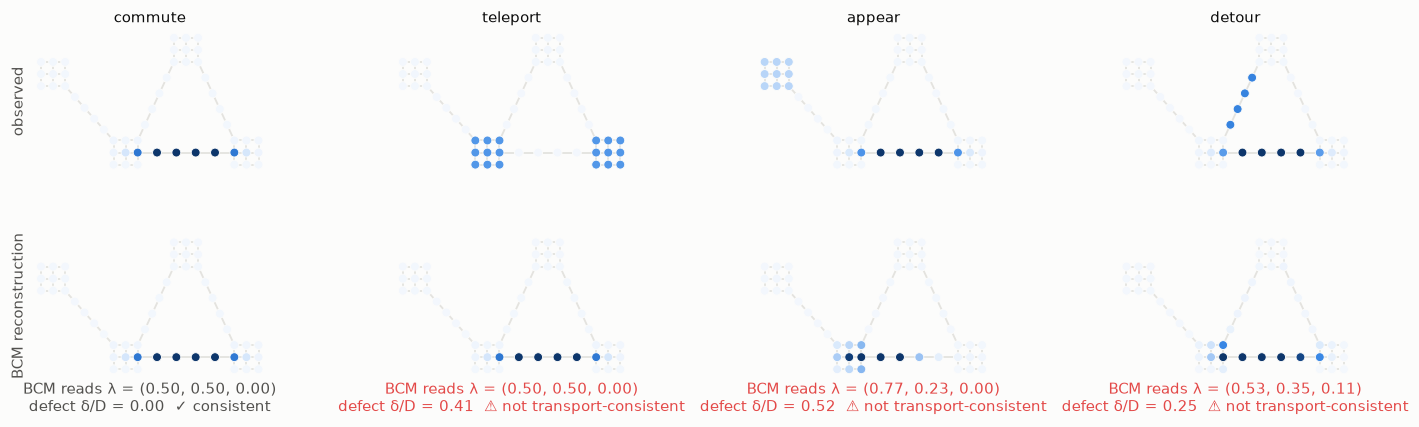

| snapshot | BCM: λ̂ (H, W, S) · defect | LOT: λ̂ (H, W, S) · defect | first-order: λ̂ (H, W, S) · defect | ℓ² unmixing: λ̂ (H, W, S) · defect | BCM: W(ν, ν̂)/D |
|---|---|---|---|---|---|
| commute | (0.50, 0.50, 0.00) · **0.00** | (0.47, 0.53, 0.00) · **0.34** | (0.50, 0.49, 0.01) · **0.46** | (0.36, 0.36, 0.27) · **0.97** | 0.00 |
| teleport | (0.50, 0.50, 0.00) · **0.41** | (0.42, 0.58, 0.00) · **0.48** | (0.50, 0.50, 0.00) · **0.00** | (0.50, 0.50, 0.00) · **0.00** | 0.37 |
| appear | (0.77, 0.23, 0.00) · **0.52** | (0.72, 0.28, 0.00) · **0.66** | (0.66, 0.33, 0.00) · **1.17** | (0.36, 0.36, 0.29) · **0.82** | 0.49 |
| detour | (0.53, 0.35, 0.11) · **0.25** | (0.53, 0.36, 0.11) · **0.21** | (0.52, 0.41, 0.07) · **0.48** | (0.36, 0.35, 0.29) · **0.82** | 0.21 |

In [6]:
def on_road(key, frac, base):
    p = np.zeros(G.n)
    p[ROADS[key]] = 1.0 / len(ROADS[key])
    return (1 - frac) * base + frac * p / PI


commute = synth([0.5, 0.5, 0.0])
SNAPS = {
    "commute": commute,
    "teleport": 0.5 * R["Home"] + 0.5 * R["Work"],
    "appear": 0.8 * commute + 0.2 * R["Harbor"],
    "detour": on_road(("Stadium", "Home"), 0.25, commute),
}
TAU = 0.15  # alarm threshold on the defect delta / D; section 5 calibrates it

scores = {name: {m: f(nu) for m, f in METHODS.items()} for name, nu in SNAPS.items()}
recon = {name: synth(scores[name]["BCM"][0]) for name in SNAPS}

fig, axes = plt.subplots(2, 4, figsize=(13, 4.4))
for j, (name, nu) in enumerate(SNAPS.items()):
    lam, d = scores[name]["BCM"]
    draw(axes[0, j], nu, name, vmax=VMAX)
    flagged = d > TAU
    draw(axes[1, j], recon[name], None, vmax=VMAX,
         note=f"BCM reads λ = ({lam[0]:.2f}, {lam[1]:.2f}, {lam[2]:.2f})\n"
              f"defect δ/D = {d:.2f}  " + ("⚠ not transport-consistent" if flagged else "✓ consistent"),
         note_color=ALERT if flagged else INK2)
axes[0, 0].text(-0.08, 0.5, "observed", transform=axes[0, 0].transAxes, rotation=90, va="center", color=INK2)
axes[1, 0].text(-0.08, 0.5, "BCM reconstruction", transform=axes[1, 0].transAxes, rotation=90, va="center",
                color=INK2)
plt.tight_layout()
plt.show()

rows = ["| snapshot | " + " | ".join(f"{m}: λ̂ (H, W, S) · defect" for m in METHODS)
        + " | BCM: W(ν, ν̂)/D |", "|---|" + "---|" * (len(METHODS) + 1)]
for name, nu in SNAPS.items():
    cells = [f"({', '.join(f'{x:.2f}' for x in lam)}) · **{d:.2f}**" for lam, d in scores[name].values()]
    w = socp(lambda N, nu=nu, name=name: np.sqrt(geodesic_socp(G, nu, recon[name], N=N).W2)) / D_W
    rows.append(f"| {name} | " + " | ".join(cells) + f" | {w:.2f} |")
display(Markdown("\n".join(rows)))

The four models disagree in an instructive way:

* The **BCM** explains the commute exactly (defect $0.00$) and reads its progress,
  $\hat\lambda = (0.5, 0.5, 0)$. It flags all three anomalies. For the teleport, its reconstruction is the
  commute that *should* have produced those district totals, with the mass on the road. The last column
  checks that $\delta$ estimates what it should: the actual transport distance from each snapshot to
  its reconstruction, $W(\nu, \nu_{\hat\lambda})$, is within a few hundredths of $D$ of $\delta$.
* **$\ell^2$ unmixing** does the opposite. The teleport is a linear mixture, so it is explained perfectly.
  The real commute is not: the mass on the road belongs to no regime, so its residual is the *largest*
  of the four, above even the Harbor gathering's.
* The **first-order transport** coding agrees with $\ell^2$ on the teleport, as the proposition in
  section 3 predicts: residual $0$. Its low-pass norm changes the other numbers but not the verdict, and it
  scores the commute about as high as the detour.
* **LOT** sits in between. Embedding at one base point (the uniform city) and coding linearly there
  partly captures transport, but it scores the commute *above* the detour. The tangent space at the
  uniform city is a poor flat chart of mass that moves between districts along thin roads.

## 5. Calibration: normal states against three kinds of anomaly

Four snapshots prove nothing about thresholds. We draw 24 normal snapshots and 24 anomalies, all with
multiplicative log-normal node noise of level $\sigma \in \{0, 0.1, 0.2, 0.3\}$, so that each
intersection's count is off by a typical factor of $e^{\pm\sigma}$:

* **normal**: BCM syntheses at random weights, a third each at a regime (a vertex of the simplex), on an
  edge of it (a transition between two regimes), and inside it;
* **teleport**: random linear mixtures of the three regimes;
* **appear**: a random normal state with 5–30% of the mass replaced by a Harbor gathering;
* **detour**: the half-done commute with 10–40% of the mass on a road the regimes never use.

48 snapshots coded four ways in 14 s (1 conic solve(s) retried at a neighboring N so far)


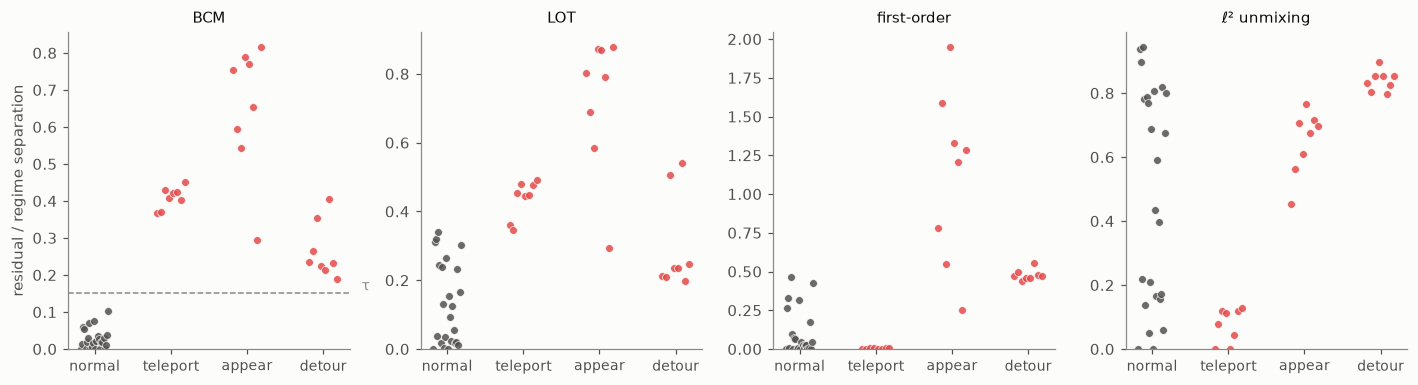

| model | AUC (anomaly vs normal) |
|---|---|
| BCM | 1.00 |
| LOT | 0.92 |
| first-order | 0.71 |
| ℓ² unmixing | 0.51 |

BCM: largest normal defect **0.101**, smallest anomalous defect **0.188**; largest error in the recovered weights of a normal snapshot **0.020** (at noise up to σ = 0.3).

In [7]:
rng = np.random.default_rng(7)
LEVELS = [0.0, 0.1, 0.2, 0.3]


def noisy(nu, s):
    p = nu * PI * np.exp(s * rng.normal(size=G.n))
    return p / p.sum() / PI


cases = []  # (kind, noise level, snapshot, true weights or None)
for k in range(24):
    # a third each at a regime, on an edge of the simplex (a transition), and inside it
    lam = [np.eye(3)[rng.integers(3)], np.insert(rng.dirichlet([1, 1]), rng.integers(3), 0.0),
           rng.dirichlet([1, 1, 1])][k % 3]
    cases.append(("normal", LEVELS[k % 4], noisy(synth(lam), LEVELS[k % 4]), lam))
for k in range(8):
    lam = rng.dirichlet([1, 1, 1])
    cases.append(("teleport", LEVELS[k % 4], noisy(sum(w * ref for w, ref in zip(lam, REFS, strict=True)),
                                                   LEVELS[k % 4]), None))
for k in range(8):
    f = rng.uniform(0.05, 0.3)
    base = synth(rng.dirichlet([1, 1, 1]))
    cases.append(("appear", LEVELS[k % 4], noisy((1 - f) * base + f * R["Harbor"], LEVELS[k % 4]), None))
for k in range(8):
    key = [("Work", "Stadium"), ("Stadium", "Home"), ("Home", "Harbor")][k % 3]
    cases.append(("detour", LEVELS[k % 4], noisy(on_road(key, rng.uniform(0.1, 0.4), commute), LEVELS[k % 4]),
                  None))

t0 = time.time()
results = [{m: f(nu) for m, f in METHODS.items()} for _, _, nu, _ in cases]
print(f"{len(cases)} snapshots coded four ways in {time.time() - t0:.0f} s "
      f"({socp.retries} conic solve(s) retried at a neighboring N so far)")

KINDS = ["normal", "teleport", "appear", "detour"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, m in zip(axes, METHODS, strict=True):
    for x, kind in enumerate(KINDS):
        d = [res[m][1] for (kd, _, _, _), res in zip(cases, results, strict=True) if kd == kind]
        jitter = np.linspace(-0.18, 0.18, len(d))
        ax.scatter(x + jitter, d, s=26, color=INK2 if kind == "normal" else ALERT, alpha=0.85,
                   edgecolors=SURFACE, linewidths=0.5)
    if m == "BCM":
        ax.axhline(TAU, color=MUTED, lw=1, ls="--")
        ax.text(3.45, TAU, " τ", color=MUTED, fontsize=9, va="bottom")
    ax.set_xticks(range(4), KINDS, rotation=0, fontsize=9)
    ax.set_title(m, fontsize=10)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("residual / regime separation")
plt.tight_layout()
plt.show()


def auc(m):
    neg = [res[m][1] for c, res in zip(cases, results, strict=True) if c[0] == "normal"]
    pos = [res[m][1] for c, res in zip(cases, results, strict=True) if c[0] != "normal"]
    return np.mean([p > q for p in pos for q in neg])


normal_bcm = [res["BCM"][1] for c, res in zip(cases, results, strict=True) if c[0] == "normal"]
anomal_bcm = [res["BCM"][1] for c, res in zip(cases, results, strict=True) if c[0] != "normal"]
err = [np.abs(res["BCM"][0] - c[3]).max() for c, res in zip(cases, results, strict=True) if c[0] == "normal"]
display(Markdown(
    "| model | AUC (anomaly vs normal) |\n|---|---|\n"
    + "\n".join(f"| {m} | {auc(m):.2f} |" for m in METHODS)
    + f"\n\nBCM: largest normal defect **{max(normal_bcm):.3f}**, smallest anomalous defect "
    f"**{min(anomal_bcm):.3f}**; largest error in the recovered weights of a normal snapshot "
    f"**{max(err):.3f}** (at noise up to σ = 0.3)."
))

The BCM separates the two populations completely (AUC 1). The largest normal defect is about $0.10$
and the smallest anomalous one about $0.19$. The threshold $\tau = 0.15$ used throughout sits in that
gap. The coordinates of normal snapshots come back within $0.02$ of the truth at every noise level.

The baselines fail in characteristic ways. $\ell^2$ unmixing is at chance (AUC about ½). It scores
teleports as perfectly normal and transitions as badly anomalous, and on average these cancel. The
first-order coding is somewhat better, because most appearances and detours score above every normal
state, but it accepts every teleport, as the proposition of section 3 says it must. LOT comes closest, but its
normal transitions
overlap its detours, so no threshold separates them.

How much noise can the defect absorb? Section 2 predicts that node noise is cheap in the transport
metric. The next cell pushes the noise level on the half-done commute far past what the calibration
used.

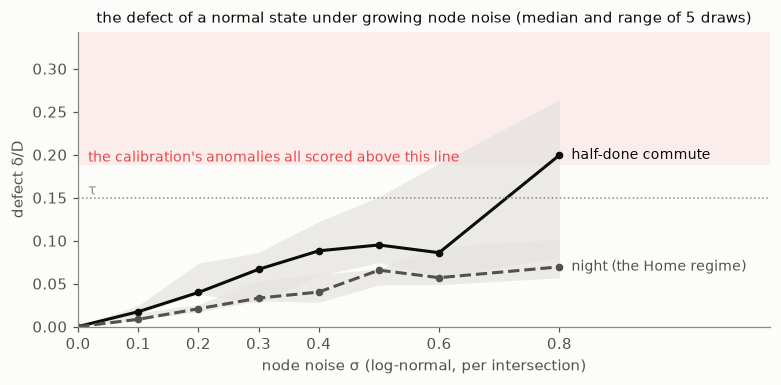

half-done commute        largest of 5 draws at each σ: 0.000 0.025 0.074 0.086 0.122 0.151 0.190 0.264
night (the Home regime)  largest of 5 draws at each σ: 0.000 0.016 0.026 0.053 0.061 0.067 0.093 0.101


In [8]:
levels = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8]
curves = {"half-done commute": commute, "night (the Home regime)": R["Home"]}
noise_runs = {name: [[code_bcm(noisy(nu, s))[1] for _ in range(5)] for s in levels] for name, nu in curves.items()}

top = 1.3 * max(max(max(d) for d in runs) for runs in noise_runs.values())
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.axhspan(min(anomal_bcm), top, color=ALERT, alpha=0.08, lw=0)
ax.text(0.01, min(anomal_bcm), " the calibration's anomalies all scored above this line", color=ALERT, fontsize=9,
        va="bottom")
for (name, runs), (c, ls) in zip(noise_runs.items(), [(INK, "-"), (INK2, "--")], strict=True):
    ax.fill_between(levels, [min(d) for d in runs], [max(d) for d in runs], color=GRID, alpha=0.7, lw=0)
    med = [np.median(d) for d in runs]
    ax.plot(levels, med, color=c, ls=ls, lw=2, marker="o", ms=4)
    ax.text(levels[-1] + 0.02, med[-1], name, color=c, fontsize=9, va="center")
ax.axhline(TAU, color=MUTED, lw=1, ls=":")
ax.text(0.01, TAU, " τ", color=MUTED, fontsize=9, va="bottom")
ax.set_xlim(0, 1.15)
ax.set_xticks(levels[:5] + [0.6, 0.8])
ax.set_xlabel("node noise σ (log-normal, per intersection)")
ax.set_ylabel("defect δ/D")
ax.set_ylim(0, top)
ax.set_title("the defect of a normal state under growing node noise (median and range of 5 draws)", fontsize=10)
plt.tight_layout()
plt.show()
for name, runs in noise_runs.items():
    print(f"{name:24s} largest of 5 draws at each σ:", " ".join(f"{max(d):.3f}" for d in runs))

Up to $\sigma = 0.4$, where each count is off by a typical factor of $1.5$, both normal states stay
below $\tau$. Beyond that the commute's defect reaches the weakest anomalies of the calibration: noise that
large costs, in transport terms, as much as a 10% detour, and the size of the defect alone can no longer
separate them. The night regime absorbs even $\sigma = 0.8$. Its mass sits on a compact block of
intersections, where noise only rearranges mass between neighbors: a high-frequency change, cheap under
the transport metric's $1/\mu_k$ response. The commute's mass is strung along a road with few
neighbors to trade with, and the same relative noise there plausibly costs more.

## 6. A day in the city

A day in 48 half-hour frames, every frame with node noise $\sigma = 0.15$:

* night at Home until 07:00, then the commute to Work until 09:00;
* office hours, with a lunch break at 12:30 when some people go home and some go toward the Stadium (an
  *interior* point of the simplex);
* from 17:00 the crowd heads to the Stadium for an evening event, and from 21:30 it goes home.

Three frames are corrupted:

* **08:00 was lost** and filled by linear interpolation of the 07:00 and 09:00 frames: a teleport;
* **14:00**: an unannounced gathering in the Harbor (20% of the mass);
* **17:30**: a road closure sends a quarter of the crowd along the Stadium–Home road.

In [9]:
HOURS = np.arange(48) / 2


def schedule(h):
    """The true weights (Home, Work, Stadium) at hour h."""
    ramp = lambda a, b: min(max((h - a) / (b - a), 0.0), 1.0)  # noqa: E731
    if h < 7:
        return np.array([1.0, 0.0, 0.0])
    if h <= 9:
        t = ramp(7, 9)
        return np.array([1 - t, t, 0.0])
    if h == 12.5:
        return np.array([0.15, 0.6, 0.25])
    if h < 17:
        return np.array([0.0, 1.0, 0.0])
    if h <= 18.5:
        t = ramp(17, 18.5)
        return np.array([0.0, 1 - t, t])
    if h < 21.5:
        return np.array([0.0, 0.0, 1.0])
    t = ramp(21.5, 23.5)
    return np.array([t, 0.0, 1 - t])


t0 = time.time()
truth = [synth(schedule(h)) for h in HOURS]
frames = [noisy(nu, 0.15) for nu in truth]
CORRUPT = {8.0: "lost frame, filled linearly", 14.0: "Harbor gathering", 17.5: "road closure detour"}
i8, i14, i175 = (int(2 * h) for h in CORRUPT)
frames[i8] = 0.5 * frames[i8 - 2] + 0.5 * frames[i8 + 2]
frames[i14] = noisy(0.8 * truth[i14] + 0.2 * R["Harbor"], 0.15)
frames[i175] = noisy(on_road(("Stadium", "Home"), 0.25, truth[i175]), 0.15)
day = [{m: METHODS[m](nu) for m in ("BCM", "LOT", "ℓ² unmixing")} for nu in frames]
print(f"48 frames synthesized and coded in {time.time() - t0:.0f} s")

48 frames synthesized and coded in 16 s


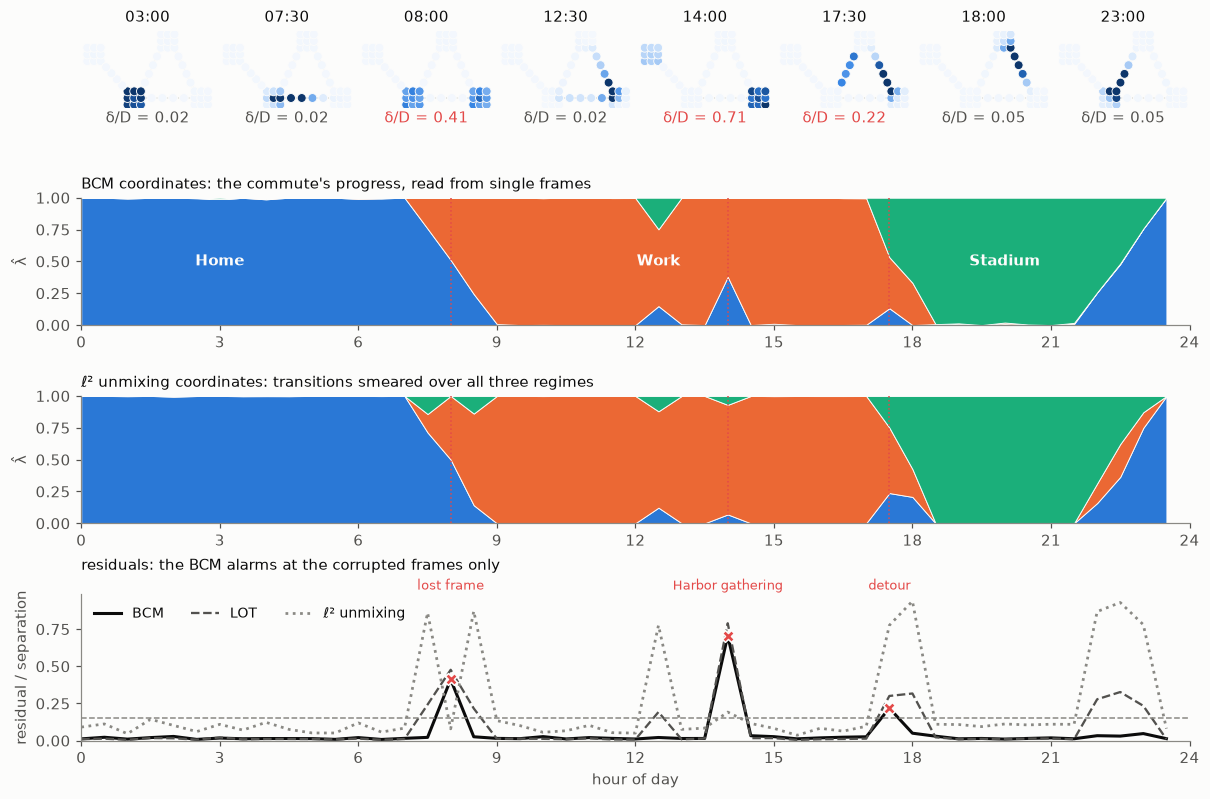

BCM alarms (δ/D > τ) at: 08:00, 14:00, 17:30
BCM          catching all three corrupted frames costs  0 false alarms out of 45
LOT          catching all three corrupted frames costs  2 false alarms out of 45 (18:00, 22:30)
ℓ² unmixing  catching all three corrupted frames costs 31 false alarms out of 45


In [10]:
fig = plt.figure(figsize=(13, 8.6))
gs = fig.add_gridspec(4, 8, height_ratios=[0.9, 1, 1, 1.15], hspace=0.55, wspace=0.05)
show = [3.0, 7.5, 8.0, 12.5, 14.0, 17.5, 18.0, 23.0]
for j, h in enumerate(show):
    ax = fig.add_subplot(gs[0, j])
    d = day[int(2 * h)]["BCM"][1]
    draw(ax, frames[int(2 * h)], f"{int(h):02d}:{int(60 * (h % 1)):02d}", vmax=VMAX,
         note=f"δ/D = {d:.2f}", note_color=ALERT if d > TAU else INK2)


def stacked(ax, key, title):
    lam = np.array([d[key][0] for d in day])
    ax.stackplot(HOURS, lam.T, colors=[REGIME_COLOR[d] for d in REGIMES], edgecolor=SURFACE, lw=0.6)
    for h in CORRUPT:
        ax.axvline(h, color=ALERT, lw=1, ls=":")
    ax.set_xlim(0, 23.5)
    ax.set_ylim(0, 1)
    ax.set_ylabel("λ̂")
    ax.set_title(title, fontsize=10, loc="left")
    ax.set_xticks(range(0, 25, 3))


ax = fig.add_subplot(gs[1, :])
stacked(ax, "BCM", "BCM coordinates: the commute's progress, read from single frames")
for d, h in [("Home", 3), ("Work", 12.5), ("Stadium", 20)]:
    ax.text(h, 0.5, d, color=SURFACE, ha="center", va="center", fontsize=10, fontweight="bold")
ax = fig.add_subplot(gs[2, :])
stacked(ax, "ℓ² unmixing", "ℓ² unmixing coordinates: transitions smeared over all three regimes")
ax = fig.add_subplot(gs[3, :])
styles = {"BCM": (INK, "-", 2), "LOT": (INK2, "--", 1.5), "ℓ² unmixing": (MUTED, ":", 1.8)}
for m, (c, ls, lw) in styles.items():
    res = [d[m][1] for d in day]
    ax.plot(HOURS, res, color=c, ls=ls, lw=lw, label=m)
ax.legend(loc="upper left", ncol=3, fontsize=9)
for h, what in {8.0: "lost frame", 14.0: "Harbor gathering", 17.5: "detour"}.items():
    ax.scatter(h, day[int(2 * h)]["BCM"][1], marker="X", s=60, color=ALERT, edgecolors=SURFACE, zorder=3)
    ax.text(h, 1.01, what, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8.5, color=ALERT)
ax.axhline(TAU, color=MUTED, lw=1, ls="--")
ax.set_xlim(0, 23.5)
ax.set_ylim(bottom=0)
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("hour of day")
ax.set_ylabel("residual / separation")
ax.set_title("residuals: the BCM alarms at the corrupted frames only", fontsize=10, loc="left", pad=16)
plt.show()

print("BCM alarms (δ/D > τ) at:", ", ".join(f"{int(h):02d}:{int(60 * (h % 1)):02d}" for i, h in enumerate(HOURS)
                                         if day[i]["BCM"][1] > TAU))
# Each model on its own scale: the highest threshold that still catches all three corrupted frames, and
# how many of the 45 clean frames it would flag along with them.
for m in styles:
    catch = min(day[int(2 * h)][m][1] for h in CORRUPT)
    false = [h for h, d in zip(HOURS, day, strict=True) if h not in CORRUPT and d[m][1] >= catch]
    at = " (" + ", ".join(f"{int(h):02d}:{int(60 * (h % 1)):02d}" for h in false) + ")" if 0 < len(false) <= 5 else ""
    print(f"{m:12s} catching all three corrupted frames costs {len(false):2d} false alarms out of 45{at}")

The BCM raises its alarm on exactly the three corrupted frames. On every other frame, including the
noisy commutes and the 12:30 three-way lunch frame, it reads the population's progress and stays quiet.
Its coordinates at the anomalies are the most plausible transport-consistent reading. At 08:00 that
reading is the half-done commute the lost frame should have shown.

The baselines are judged on their own scales in the printout: each needs a threshold low enough to
catch all three corrupted frames. $\ell^2$ unmixing then flags most of the clean frames too, because
every transition is "unexplained" by a linear mixture, while the linearly filled 08:00 frame looks
almost perfect. LOT does far better here, with two false alarms. They fall on transition frames, where
its flat chart at the uniform city is least accurate.

The same story on the simplex: the BCM's coordinates trace the day along the triangle's edges (each
transition is a geodesic between two regimes) and dip inside only for lunch. $\ell^2$ unmixing's
coordinates cut through the middle of the triangle on every transition.

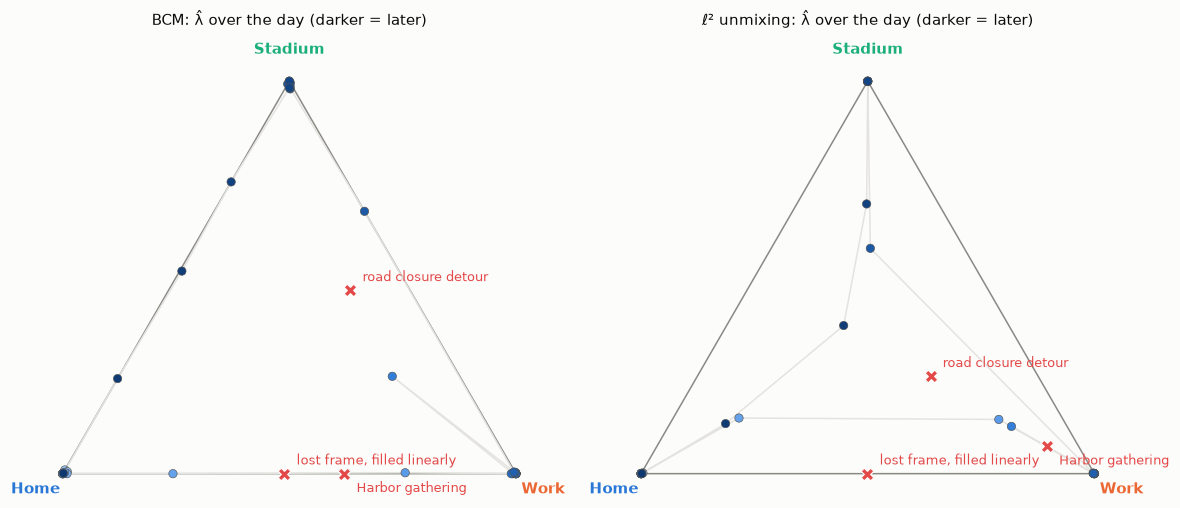

In [11]:
CORNERS = np.array([[0.0, 0.0], [1.0, 0.0], [0.5, np.sqrt(3) / 2]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, m in zip(axes, ["BCM", "ℓ² unmixing"], strict=True):
    ax.add_patch(plt.Polygon(CORNERS, closed=True, fill=False, edgecolor=MUTED, lw=1))
    for d, c in zip(REGIMES, CORNERS, strict=True):
        ax.text(*(c + (c - CORNERS.mean(0)) * 0.12), d, color=REGIME_COLOR[d], ha="center", va="center",
                fontsize=10, fontweight="bold")
    P = np.array([d[m][0] for d in day]) @ CORNERS
    ok = [i for i in range(48) if HOURS[i] not in CORRUPT]
    ax.plot(P[ok, 0], P[ok, 1], color=GRID, lw=1, zorder=1)
    ax.scatter(P[ok, 0], P[ok, 1], c=HOURS[ok], cmap=MASS, vmin=-6, vmax=24, s=30, edgecolors=INK2,
               linewidths=0.4, zorder=2)
    for h, what in CORRUPT.items():
        i = int(2 * h)
        ax.scatter(*P[i], marker="X", s=70, color=ALERT, edgecolors=SURFACE, linewidths=0.8, zorder=3)
        ax.annotate(what, P[i], xytext=(8, -12 if h == 14.0 else 6), textcoords="offset points", fontsize=8.5,
                    color=ALERT)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{m}: λ̂ over the day (darker = later)", fontsize=10, pad=24)
plt.tight_layout()
plt.show()

## 7. Repairing a missing frame

The 08:00 frame was lost and filled by linear interpolation of its neighbors, the usual default for
missing samples of a time series. The defect flags the filled frame, and the BCM also suggests a better
fill: **interpolate the coordinates, then synthesize.**

$$\hat\nu_{08:00} = \nu_{\bar\lambda},
  \qquad \bar\lambda = \tfrac12\big(\hat\lambda_{07:00} + \hat\lambda_{09:00}\big).$$

This is displacement interpolation carried out inside the model. It moves the population along the road
instead of fading one district out and another in. On noise-free frames, the cell below compares both
fills with the true 08:00 state, and then asks how far apart the neighboring frames must be before linear
interpolation becomes detectable.

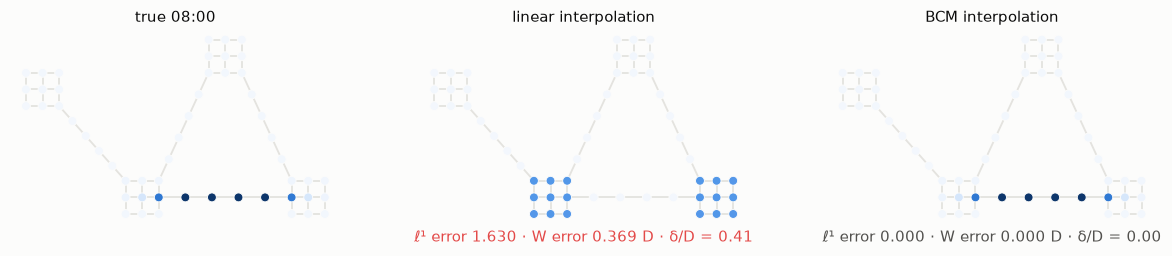

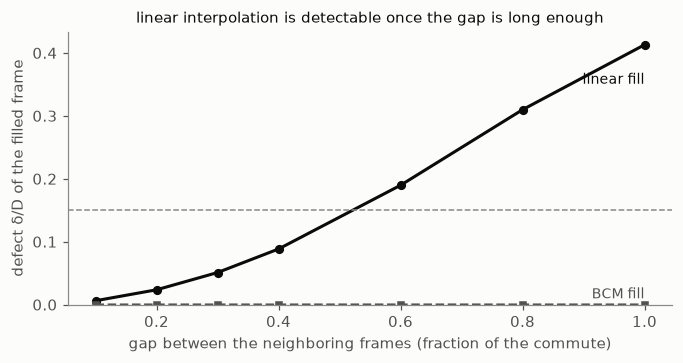

In [12]:
lam7, lam9 = code_bcm(truth[i8 - 2])[0], code_bcm(truth[i8 + 2])[0]
fills = {
    "linear interpolation": 0.5 * truth[i8 - 2] + 0.5 * truth[i8 + 2],
    "BCM interpolation": synth(0.5 * (lam7 + lam9)),
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
draw(axes[0], truth[i8], "true 08:00", vmax=VMAX)
for ax, (name, x) in zip(axes[1:], fills.items(), strict=True):
    W = gt.transport_cost(G, x, truth[i8], method="socp")
    l1 = np.abs((x - truth[i8]) * PI).sum()
    d = code_bcm(x)[1]
    draw(ax, x, name, vmax=VMAX, note=f"ℓ¹ error {l1:.3f} · W error {W / D_W:.3f} D · δ/D = {d:.2f}",
         note_color=ALERT if d > TAU else INK2)
plt.tight_layout()
plt.show()

# linear fills of the commute's midpoint from frames t = 1/2 -+ gap/2 apart (noise-free)
gaps = [0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0]
d_lin, d_bcm = [], []
for gap in gaps:
    a, b = synth([0.5 + gap / 2, 0.5 - gap / 2, 0]), synth([0.5 - gap / 2, 0.5 + gap / 2, 0])
    d_lin.append(code_bcm(0.5 * a + 0.5 * b)[1])
    la, lb = code_bcm(a)[0], code_bcm(b)[0]
    d_bcm.append(code_bcm(synth(0.5 * (la + lb)))[1])
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(gaps, d_lin, color=INK, lw=2, marker="o", ms=5)
ax.plot(gaps, d_bcm, color=INK2, lw=1.5, ls="--", marker="s", ms=4)
ax.text(gaps[-1], d_lin[-1] * 0.85, "linear fill", color=INK, ha="right", fontsize=9)
ax.text(gaps[-1], d_bcm[-1] + 0.01, "BCM fill", color=INK2, ha="right", fontsize=9)
ax.axhline(TAU, color=MUTED, lw=1, ls="--")
ax.set_xlabel("gap between the neighboring frames (fraction of the commute)")
ax.set_ylabel("defect δ/D of the filled frame")
ax.set_ylim(bottom=0)
ax.set_title("linear interpolation is detectable once the gap is long enough", fontsize=10)
plt.tight_layout()
plt.show()

The BCM fill reproduces the true frame up to the SOCP's solver tolerance. The linear fill puts half the
population in each district and nobody on the road. Its $\ell^1$ error is about $1.6$ out of a possible
$2$: most of the mass is in the wrong place. The defect of a linear fill grows with the gap it bridges.
Over short gaps, a linear fill is a good local approximation of a geodesic and passes. Once the gap is
about half the commute or more, it becomes a detectable teleport.

## 8. Discussion

**What is new here.** The BCM was introduced as a model for synthesizing and coding measures, and
`graphtransport` computes it on graphs. In GSP, optimal transport has mostly served to *compare* graphs
or signals on them (Petric Maretic et al. 2019; Tong et al. 2021). Barycentric coordinates were first
computed for histograms with entropic transport (Bonneel, Peyré & Cuturi 2016), and barycenters have
been proposed for representing graph signals (Simou & Frossard 2018), and the linearized transport metric on
graphs has been studied as a
resistance distance (Robertson, Wan & Cloninger 2024). This notebook uses the *analysis* step's residual,
the barycentric defect $\delta = \tfrac12\|\nabla J_{\hat\lambda}\|$, as a **test of transport-consistency**
for graph signals: a test of whether a state is reachable by moving mass among known regimes along the
graph. We are not aware of earlier work that does this. Two properties make it work:

1. **Kinematics.** In the Maas/CHLZ metric, mass can only move along edges, and an empty road is
   expensive to cross. A barycenter therefore puts mass in transit where a real population would be,
   and a mixture of regimes is not a barycenter.
2. **Spectral robustness.** Locally the metric is the $1/\mu_k$ (inverse-Laplacian) graph filter, so
   uncorrelated node noise, which is mostly high-frequency, barely moves the defect.

The second property alone is not enough. Any first-order version of the test is linear unmixing in a
different norm, and it accepts teleports. The test needs the nonlinear log map, and on graphs that
requires a solver for the discrete transport problem. `graphtransport` provides one.

**Where this could apply.** Any nonnegative quantity that moves along a network, observed in snapshots,
with a few recurring regimes. Examples: pedestrian or bike-share counts on a street graph,
occupancy of a building's rooms and corridors, traffic on a transit network, load on a power or
communication network, or a contaminant in a river network. The defect validates sensor fusion and
interpolated or imputed frames. It detects "mass from nowhere" (an unannounced event, a leak, a sensor
fault), and it flags flows on unexpected routes.

**Limitations and open questions.**

* *Cost.* Analysis takes one geodesic solve per regime per snapshot: about 0.2 s here, on 52 nodes. It
  is SOCP at $N = 10$, so its time discretization is coarse, but synthesis and analysis use the same
  discretization and so remain consistent. Scaling to city-size graphs would need a faster log map,
  such as a Jacobian-free Newton–Krylov shooting solver.
* *Positivity.* Shooting needs strictly positive densities. A background floor stands in for "somebody
  is always somewhere"; real counts with true zeros need the SOCP or a mollified log map.
* *Calibration.* The threshold $\tau$ was set from synthetic normal states. With real data it should come
  from a held-out set of normal frames. The distribution of $\delta$ under a noise model is an open
  statistical question (compare the estimation theory of Werenski et al. 2022).
* *The dictionary.* The regimes were given. Learning them (Wasserstein dictionary learning, with
  the analysis defect as the fit criterion) is a natural next step, as is *localizing* an anomaly: which
  edges or nodes carry the defect. The defect's own potential $\sum_i \hat\lambda_i\varphi_i$ mixes the
  anomaly with the shift in $\hat\lambda$ it causes, so it does not point at the anomaly cleanly.
* *Unbalanced mass.* A gathering that adds people, rather than moving them, changes total mass. The
  model sees only the normalized distribution. An unbalanced transport metric would separate "more
  people" from "people elsewhere".

### References

* J. Maas. Gradient flows of the entropy for finite Markov chains. *J. Funct. Anal.* 261 (8), 2011.
* S.-N. Chow, W. Huang, Y. Li, H. Zhou. Fokker–Planck equations for a free energy functional or Markov
  process on a graph. *Arch. Ration. Mech. Anal.* 203 (3), 2012.
* M. Werenski, R. Jiang, A. Tasissa, S. Aeron, J. M. Murphy. Measure estimation in the barycentric coding
  model. *ICML*, 2022.
* M. Werenski, B. Mallery, S. Aeron, J. M. Murphy. Linearized Wasserstein barycenters: synthesis, analysis,
  representational capacity, and applications. *AISTATS*, 2025.
* D. Gentile, J. M. Murphy. Static and dynamic approaches to computing barycenters of probability measures
  on graphs. arXiv:2603.26940, 2026.
* S. Robertson, Z. Wan, A. Cloninger. Resistance distance and linearized optimal transport on graphs.
  arXiv:2404.15261, 2024.
* E. Simou, P. Frossard. Graph signal representation with Wasserstein barycenters. arXiv:1812.05517, 2018.
* W. Wang, D. Slepčev, S. Basu, J. A. Ozolek, G. K. Rohde. A linear optimal transportation framework for
  quantifying and visualizing variations in sets of images. *Int. J. Comput. Vis.* 101 (2), 2013.
* N. Bonneel, G. Peyré, M. Cuturi. Wasserstein barycentric coordinates: histogram regression using optimal
  transport. *ACM Trans. Graph.* 35 (4), 2016.
* D. I. Shuman, S. K. Narang, P. Frossard, A. Ortega, P. Vandergheynst. The emerging field of signal
  processing on graphs. *IEEE Signal Process. Mag.* 30 (3), 2013.
* A. Ortega, P. Frossard, J. Kovačević, J. M. F. Moura, P. Vandergheynst. Graph signal processing:
  overview, challenges, and applications. *Proc. IEEE* 106 (5), 2018.
* N. Keshava, J. F. Mustard. Spectral unmixing. *IEEE Signal Process. Mag.* 19 (1), 2002.
* H. Petric Maretic, M. El Gheche, G. Chierchia, P. Frossard. GOT: an optimal transport framework for
  graph comparison. *NeurIPS*, 2019.
* A. Tong et al. Diffusion earth mover's distance and distribution embeddings. *ICML*, 2021.